# Double Slit: metapolicy + pool-feedback on a wind-stochastic domain, 4th data point

Same comparison as `SFOLS/04_resource_gathering.ipynb` (GPI vs. metapolicy vs.
pool-fed-back GPI, evaluated exactly), now on `DoubleSlit-v0` from
`RM/sf-fsa-vi/envs/grid_envs.py` -- a domain already vendored and used in this repo's
own ICAPS-2024-paper experiments (`fsa_double_slit1`), not a new pick from an external
library. The agent starts at the left edge of a long corridor and always drifts
rightward; a uniform "wind" perturbs the vertical position by `-max_wind..+max_wind`
at every step (`2*max_wind+1` equally likely outcomes), and the episode ends on
reaching one of two exits (`O1` top-right, `O2` bottom-right). 2 objectives, genuinely
stochastic by construction (not an add-on the way Resource Gathering's enemy-death
probability was), and a corridor-navigation structure unlike anything tested so far.

This reuses the actual vendored `DoubleSlit` class's own transition method
(`coords_act_transition_distr`) rather than re-deriving the wind-walk logic by hand --
lower risk of a subtle bug, and consistent with how the domain is actually defined
elsewhere in this repo.

Three data points so far:
- **DST**: metapolicy already optimal (ceiling) -- nothing for pool-feedback to close.
- **Office**: real gap (up to 0.22) -- pool-feedback closes it *exactly* to GPI, never
  past it.
- **Resource Gathering**: no gap at all (metapolicy == GPI at every k) -- again nothing
  to close, for a different reason (a single canonical policy carries almost no
  information here, so there's nothing for either method to differentiate on).

Open question: does Double Slit's wind create the kind of state-dependent tradeoff that
actually makes `B(s)` bind, or does it land in one of the two "nothing to close"
categories again?

## 1. Domain: the actual vendored DoubleSlit-v0 environment

In [1]:
import os
import sys
import time

import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(suppress=True, precision=4)

SF_FSA_VI_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", "RM", "sf-fsa-vi"))
if SF_FSA_VI_ROOT not in sys.path:
    sys.path.insert(0, SF_FSA_VI_ROOT)

import gym as old_gym
import envs  # noqa: F401 -- registers DoubleSlit-v0 in old gym

GAMMA = 0.99
SEED = 0

core = old_gym.make("DoubleSlit-v0").unwrapped
N_ACTIONS = core.a_dim
FEAT_DIM = core.feat_dim
START_STATE = core.initial[0]

slit_states = list(core.state_to_coords.values())
slit_state_idx = {s: i for i, s in enumerate(slit_states)}
n_slit_states = len(slit_states)
is_terminal = {s: s in core.object_ids for s in slit_states}
nonterminal = [s for s in slit_states if not is_terminal[s]]

print(f"{n_slit_states} states ({len(nonterminal)} non-terminal), {N_ACTIONS} actions, "
      f"{FEAT_DIM} objectives, max_wind={core._max_wind}")
print(f"start={START_STATE}  exits={core.exit_states}")

535 states (533 non-terminal), 3 actions, 2 objectives, max_wind=1
start=(10, 0)  exits={0: (0, 28), 1: (20, 28)}


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/opt/anaconda3/envs/okb/lib/python3.10/site-packages/gym/envs/registration.py:505: UserWarning: WARN: The environment DoubleSlit-v0 is out of date. You should consider upgrading to version `v1` with the environment ID `DoubleSlit-v1`.
  logger.warn(
/opt/anaconda3/envs/okb/lib/python3.10/site-packages/gym/spaces/box.py:84: UserWarning: WARN: Box bound precision lowered by casting to float32
  logger.warn(f"Box bound precision lowered by casting to {self.dtype}")


In [2]:
def slit_step_dist(s, a):
    """Exact outcome distribution for one step, reusing the REAL DoubleSlit env's own
    wind-transition method and reward-feature logic directly (not reimplemented) --
    returns a list of (prob, next_state, phi, terminal), matching the convention used
    in SFOLS/04_resource_gathering.ipynb's resource_step_dist."""
    outcomes = []
    for ns, prob in core.coords_act_transition_distr(s, a):
        phi = core.features(s, a, ns)
        term = ns in core.object_ids
        outcomes.append((prob, None if term else ns, phi, term))
    return outcomes


# sanity check: probabilities must sum to 1 for every (state, action)
bad = [(s, a) for s in nonterminal for a in range(N_ACTIONS)
       if not np.isclose(sum(p for p, *_ in slit_step_dist(s, a)), 1.0)]
print(f"transition sanity check: {len(bad)} (state, action) pairs with probabilities not summing to 1")

transition sanity check: 0 (state, action) pairs with probabilities not summing to 1


## 2. Exact stochastic policy iteration + SF solves

In [3]:
class SFTable:
    def __init__(self, num_actions, feat_dim, default_vec):
        self.default_vec = default_vec
        self.table = {}

    def __getitem__(self, state):
        if state not in self.table:
            self.table[state] = self.default_vec.copy()
        return self.table[state]


def policy_iteration(w, gamma=GAMMA):
    """Exact policy iteration under genuine transition probabilities -- same
    construction as SFOLS/04_resource_gathering.ipynb's version, using
    slit_step_dist's probability-weighted outcomes instead of a single successor."""
    policy = {s: 0 for s in nonterminal}
    while True:
        A, b = np.eye(n_slit_states), np.zeros(n_slit_states)
        for s in nonterminal:
            i = slit_state_idx[s]
            for prob, ns, phi, term in slit_step_dist(s, policy[s]):
                b[i] += prob * (phi @ w)
                if not term:
                    A[i, slit_state_idx[ns]] -= gamma * prob
        v = np.linalg.solve(A, b)
        V = {s: v[slit_state_idx[s]] for s in slit_states}

        stable = True
        for s in nonterminal:
            qs = []
            for a in range(N_ACTIONS):
                q = 0.0
                for prob, ns, phi, term in slit_step_dist(s, a):
                    q += prob * (phi @ w + (0.0 if term else gamma * V[ns]))
                qs.append(q)
            best_a = int(np.argmax(qs))
            stable &= best_a == policy[s]
            policy[s] = best_a
        if stable:
            return policy, V


def solve_task_exact(w, gamma=GAMMA):
    policy, _ = policy_iteration(w, gamma)
    A, b = np.eye(n_slit_states), np.zeros((n_slit_states, FEAT_DIM))
    for s in nonterminal:
        i = slit_state_idx[s]
        for prob, ns, phi, term in slit_step_dist(s, policy[s]):
            b[i] += prob * phi
            if not term:
                A[i, slit_state_idx[ns]] -= gamma * prob
    V_vec = np.linalg.solve(A, b)
    V_vec = {s: V_vec[slit_state_idx[s]] for s in slit_states}

    psi = SFTable(N_ACTIONS, FEAT_DIM, np.zeros((N_ACTIONS, FEAT_DIM)))
    for s in nonterminal:
        table = np.zeros((N_ACTIONS, FEAT_DIM))
        for a in range(N_ACTIONS):
            for prob, ns, phi, term in slit_step_dist(s, a):
                table[a] += prob * (phi if term else phi + gamma * V_vec[ns])
        psi.table[s] = table
    return psi


def evaluate_fixed_policy_scalar(action_fn, w, gamma=GAMMA):
    A, b = np.eye(n_slit_states), np.zeros(n_slit_states)
    for s in nonterminal:
        i = slit_state_idx[s]
        for prob, ns, phi, term in slit_step_dist(s, action_fn(s)):
            b[i] += prob * (phi @ w)
            if not term:
                A[i, slit_state_idx[ns]] -= gamma * prob
    v = np.linalg.solve(A, b)
    return {s: v[slit_state_idx[s]] for s in slit_states}


t0 = time.perf_counter()
_, V_check = policy_iteration(np.array([1.0, 0.0]))
print(f"sanity solve (w=[1,0], maximize reaching O1): "
      f"V(start)={V_check[START_STATE]:.4f}  ({time.perf_counter()-t0:.2f}s)")

sanity solve (w=[1,0], maximize reaching O1): V(start)=0.8231  (0.43s)


## Part 1 -- The canonical corner-weight basis

In [4]:
t0 = time.perf_counter()
Pi_canon, W_canon = [], []
for i in range(FEAT_DIM):
    w_i = np.zeros(FEAT_DIM)
    w_i[i] = 1.0
    Pi_canon.append(solve_task_exact(w_i))
    W_canon.append(w_i)
print(f"solved the {FEAT_DIM} canonical corner policies in {time.perf_counter()-t0:.2f}s")

for i, w_i in enumerate(W_canon):
    _, V = policy_iteration(w_i)
    print(f"w=e_{i} ({w_i}): V*(start)={V[START_STATE]:.4f}")

solved the 2 canonical corner policies in 1.34s


w=e_0 ([1. 0.]): V*(start)=0.8231


w=e_1 ([0. 1.]): V*(start)=0.8231


## Part 2 -- Certified/adaptive: metapolicy over the restricted stochastic meta-MDP

In [5]:
def own_greedy_actions(sf_table, w):
    return {s: int(np.argmax(sf_table[s] @ w)) for s in nonterminal}


def meta_policy_iteration_warm(w, Pi_base, W_base, gamma=GAMMA, gpi_init=True, max_sweeps=500):
    own_actions = [own_greedy_actions(sft, w_j) for sft, w_j in zip(Pi_base, W_base)]
    if gpi_init:
        meta_policy = {}
        for s in nonterminal:
            vals = [Pi_base[j][s][own_actions[j][s]] @ w for j in range(len(Pi_base))]
            meta_policy[s] = int(np.argmax(vals))
    else:
        meta_policy = {s: 0 for s in nonterminal}

    n_sweeps = 0
    while True:
        n_sweeps += 1
        A, b = np.eye(n_slit_states), np.zeros(n_slit_states)
        for s in nonterminal:
            i = slit_state_idx[s]
            for prob, ns, phi, term in slit_step_dist(s, own_actions[meta_policy[s]][s]):
                b[i] += prob * (phi @ w)
                if not term:
                    A[i, slit_state_idx[ns]] -= gamma * prob
        v = np.linalg.solve(A, b)
        V = {s: v[slit_state_idx[s]] for s in slit_states}

        stable = True
        for s in nonterminal:
            qs = []
            for j in range(len(Pi_base)):
                q = 0.0
                for prob, ns, phi, term in slit_step_dist(s, own_actions[j][s]):
                    q += prob * (phi @ w + (0.0 if term else gamma * V[ns]))
                qs.append(q)
            best_j = int(np.argmax(qs))
            stable &= best_j == meta_policy[s]
            meta_policy[s] = best_j
        if stable or n_sweeps >= max_sweeps:
            return meta_policy, V, own_actions, n_sweeps


def meta_policy_sf(meta_policy, own_actions, gamma=GAMMA):
    A, b = np.eye(n_slit_states), np.zeros((n_slit_states, FEAT_DIM))
    for s in nonterminal:
        i = slit_state_idx[s]
        for prob, ns, phi, term in slit_step_dist(s, own_actions[meta_policy[s]][s]):
            b[i] += prob * phi
            if not term:
                A[i, slit_state_idx[ns]] -= gamma * prob
    Psi_arr = np.linalg.solve(A, b)
    return {s: Psi_arr[slit_state_idx[s]] for s in slit_states}


def meta_policy_sf_full(meta_policy, own_actions, gamma=GAMMA, Psi_own=None):
    if Psi_own is None:
        Psi_own = meta_policy_sf(meta_policy, own_actions, gamma)
    table = SFTable(N_ACTIONS, FEAT_DIM, np.zeros((N_ACTIONS, FEAT_DIM)))
    for s in nonterminal:
        full = np.zeros((N_ACTIONS, FEAT_DIM))
        for a in range(N_ACTIONS):
            for prob, ns, phi, term in slit_step_dist(s, a):
                full[a] += prob * (phi if term else phi + gamma * Psi_own[ns])
        table.table[s] = full
    return table


def bellman_gap(w, V_meta, gamma=GAMMA):
    gaps = {}
    for s in nonterminal:
        qs = []
        for a in range(N_ACTIONS):
            q = 0.0
            for prob, ns, phi, term in slit_step_dist(s, a):
                q += prob * (phi @ w + (0.0 if term else gamma * V_meta[ns]))
            qs.append(q)
        gaps[s] = max(qs) - V_meta[s]
    return gaps


meta_policy, V_meta, own_actions, n_sweeps = meta_policy_iteration_warm(np.array([0.5, 0.5]), Pi_canon, W_canon)
worst_gap = max(bellman_gap(np.array([0.5, 0.5]), V_meta).values())
print(f"sanity check, w=[0.5, 0.5]: metapolicy V(start)={V_meta[START_STATE]:.4f}, "
      f"{n_sweeps} sweeps, max Bellman gap={worst_gap:.6f}")

sanity check, w=[0.5, 0.5]: metapolicy V(start)=0.4139, 3 sweeps, max Bellman gap=0.001457


## Part 3 -- GPI vs. metapolicy vs. pool-fed-back GPI, as the canonical basis grows

Same design as the Office and Resource Gathering versions of this experiment: at basis
size k, take the first k canonical corner policies and combine them via full-action-set
GPI, restricted-iterated metapolicy, and GPI over a pool grown by folding certified
metapolicies (built from a separate `build_weights` sample) back in.

In [6]:
def gpi_full_actions(Pi, w):
    actions = {}
    for s in nonterminal:
        vals = [max(psi[s][a] @ w for psi in Pi) for a in range(N_ACTIONS)]
        actions[s] = int(np.argmax(vals))
    return actions


def gpi_value(Pi_snapshot, w, gamma=GAMMA):
    actions = gpi_full_actions(Pi_snapshot, w)
    return evaluate_fixed_policy_scalar(lambda s: actions[s], w, gamma)


def metapolicy_value(Pi_base, W_base, w, gamma=GAMMA):
    _, V, _, _ = meta_policy_iteration_warm(w, Pi_base, W_base, gamma)
    return V


def mean_value(value_fn, test_weights):
    return float(np.mean([value_fn(w)[START_STATE] for w in test_weights]))


N_TEST_WEIGHTS = 101
test_w0 = np.linspace(0.0, 1.0, N_TEST_WEIGHTS)
test_weights = [np.array([w0, 1 - w0]) for w0 in test_w0]

t0 = time.perf_counter()
optimal_mean = mean_value(lambda w: policy_iteration(w)[1], test_weights)
print(f"optimal_mean = {optimal_mean:.4f}  ({time.perf_counter()-t0:.1f}s, {N_TEST_WEIGHTS} test weights)")

ks = np.arange(1, FEAT_DIM + 1)
gpi_curve, metapolicy_curve = [], []
t0 = time.perf_counter()
for k in ks:
    Pi_k, W_k = Pi_canon[:k], W_canon[:k]
    gpi_curve.append(mean_value(lambda w, Pi_k=Pi_k: gpi_value(Pi_k, w), test_weights))
    metapolicy_curve.append(mean_value(lambda w, Pi_k=Pi_k, W_k=W_k: metapolicy_value(Pi_k, W_k, w), test_weights))
    print(f"k={k}: GPI={gpi_curve[-1]:.4f}  metapolicy={metapolicy_curve[-1]:.4f}")
print(f"computed in {time.perf_counter()-t0:.1f}s")

optimal_mean = 0.6194  (48.0s, 101 test weights)


k=1: GPI=0.4116  metapolicy=0.4116


k=2: GPI=0.6194  metapolicy=0.6194
computed in 15.6s


In [7]:
def grow_pool_with_metapolicy_feedback(Pi_base, W_base, build_weights, gamma=GAMMA, cert_tol=1e-6):
    Pi_base, W_base = list(Pi_base), list(W_base)
    n_certified = n_added = 0
    t_restricted_pi = t_meta_sf_solve = t_pool_feedback = 0.0

    for w in build_weights:
        t0 = time.perf_counter()
        meta_policy, V, own_actions, _ = meta_policy_iteration_warm(w, Pi_base, W_base, gamma)
        worst_gap = max(bellman_gap(w, V, gamma).values())
        t_restricted_pi += time.perf_counter() - t0
        certified = worst_gap <= cert_tol

        if certified:
            n_certified += 1
            t0 = time.perf_counter()
            Psi_own = meta_policy_sf(meta_policy, own_actions, gamma)
            t_meta_sf_solve += time.perf_counter() - t0

            t0 = time.perf_counter()
            Pi_base.append(meta_policy_sf_full(meta_policy, own_actions, gamma, Psi_own=Psi_own))
            W_base.append(w)
            t_pool_feedback += time.perf_counter() - t0
            n_added += 1

    stats = dict(n_certified=n_certified, n_uncertified=len(build_weights) - n_certified, n_added=n_added)
    timing = dict(t_restricted_pi=t_restricted_pi, t_meta_sf_solve=t_meta_sf_solve, t_pool_feedback=t_pool_feedback)
    return Pi_base, W_base, stats, timing


N_BUILD_WEIGHTS = 30
rng_build = np.random.default_rng(SEED + 1)
build_weights = [rng_build.dirichlet(np.ones(FEAT_DIM)) for _ in range(N_BUILD_WEIGHTS)]

pooled_curve, pool_sizes, pool_stats_by_k, pool_timing_by_k = [], [], [], []
t0 = time.perf_counter()
for k in ks:
    Pi_k, W_k = Pi_canon[:k], W_canon[:k]
    Pi_grown, W_grown, stats_k, timing_k = grow_pool_with_metapolicy_feedback(Pi_k, W_k, build_weights)
    pooled_curve.append(mean_value(lambda w, Pi=Pi_grown: gpi_value(Pi, w), test_weights))
    pool_sizes.append(len(Pi_grown))
    pool_stats_by_k.append(stats_k)
    pool_timing_by_k.append(timing_k)
    print(f"k={k}: pool grew {k} -> {len(Pi_grown)}  "
          f"({stats_k['n_added']}/{N_BUILD_WEIGHTS} build weights certified & added)  "
          f"pooled+GPI={pooled_curve[-1]:.4f}")
print(f"computed in {time.perf_counter()-t0:.1f}s")

k=1: pool grew 1 -> 19  (18/30 build weights certified & added)  pooled+GPI=0.4116


k=2: pool grew 2 -> 31  (29/30 build weights certified & added)  pooled+GPI=0.6194
computed in 35.1s


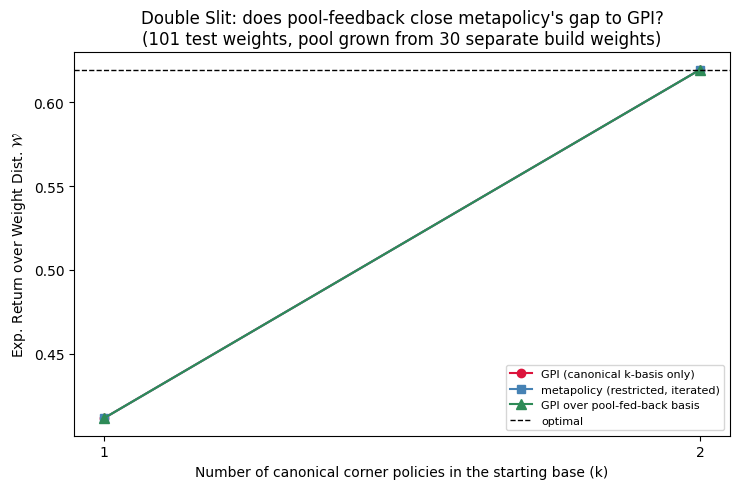

  k    GPI gap   metapolicy gap   pooled gap   % of metapolicy-GPI gap closed
  1     0.2079           0.2079       0.2079                             0.0%
  2     0.0000           0.0000       0.0000                            -8.6%

is pool-feedback actually cheap here too? (summed across all k)
restricted PI + gap check (baseline cost, shared)                :    13.60s  ( 85.2%)
meta_policy_sf linear solve (needed for ANY certify check anyway):     0.67s  (  4.2%)
extend to full table + append to pool (the ONLY new cost)        :     1.69s  ( 10.6%)
total                                                            :    15.96s

incremental pool-feedback cost per policy actually added to the pool: 35.93 ms


In [8]:
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(ks, gpi_curve, marker="o", ms=6, color="crimson", label="GPI (canonical k-basis only)")
ax.plot(ks, metapolicy_curve, marker="s", ms=6, color="steelblue", label="metapolicy (restricted, iterated)")
ax.plot(ks, pooled_curve, marker="^", ms=7, color="seagreen", label="GPI over pool-fed-back basis")
ax.axhline(optimal_mean, color="black", ls="--", lw=1, label="optimal")
ax.set_xlabel("Number of canonical corner policies in the starting base (k)")
ax.set_ylabel(r"Exp. Return over Weight Dist. $\mathcal{W}$")
ax.set_title(f"Double Slit: does pool-feedback close metapolicy's gap to GPI?\n"
             f"({N_TEST_WEIGHTS} test weights, pool grown from {N_BUILD_WEIGHTS} separate build weights)")
ax.set_xticks(ks)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

gap_metapolicy = [optimal_mean - v for v in metapolicy_curve]
gap_gpi = [optimal_mean - v for v in gpi_curve]
gap_pooled = [optimal_mean - v for v in pooled_curve]
closed_frac = [(gm - gp) / gm if gm > 1e-9 else float("nan") for gm, gp in zip(gap_metapolicy, gap_pooled)]

print(f"{'k':>3} {'GPI gap':>10} {'metapolicy gap':>16} {'pooled gap':>12} {'% of metapolicy-GPI gap closed':>32}")
for k, gm, gg, gp, cf in zip(ks, gap_metapolicy, gap_gpi, gap_pooled, closed_frac):
    print(f"{k:>3} {gg:>10.4f} {gm:>16.4f} {gp:>12.4f} {100*cf:>31.1f}%")

sep = "=" * 70
print(f"\n{sep}")
print("is pool-feedback actually cheap here too? (summed across all k)")
print(sep)
total_timing = {key: sum(t[key] for t in pool_timing_by_k) for key in pool_timing_by_k[0]}
total_added = sum(s["n_added"] for s in pool_stats_by_k)
total_t = sum(total_timing.values())
labels = {
    "t_restricted_pi": "restricted PI + gap check (baseline cost, shared)",
    "t_meta_sf_solve": "meta_policy_sf linear solve (needed for ANY certify check anyway)",
    "t_pool_feedback": "extend to full table + append to pool (the ONLY new cost)",
}
for key, v in total_timing.items():
    print(f"{labels[key]:65s}: {v:8.2f}s  ({100*v/total_t:5.1f}%)")
print(f"{'total':65s}: {total_t:8.2f}s")
if total_added > 0:
    print(f"\nincremental pool-feedback cost per policy actually added to the pool: "
          f"{1000*total_timing['t_pool_feedback']/total_added:.2f} ms")